# Prvi domaći

Uvoz potrebih biblioteka

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from time import time

Definicija naše funkcije koju želimo da minimiziramo

In [3]:
def f(x):
    x1, x2, x3 = x
    return (4/3) * (x1**2 + x2**2 - x1*x2)**0.75 + abs(x3)

Simulirano kaljenje

In [15]:
def simulirano_kaljenje(T0=1.0, alpha=0.995, T_min=1e-5,
                        sigma=0.1, n_iter=50000, seed=None):
    rng = np.random.default_rng(seed)
 
    x = rng.uniform(-1, 1, size=3) 
    f_curr = f(x)
    x_best, f_best = x.copy(), f_curr
 
    T = T0 
    istorija_f = [f_curr]
    istorija_temp = [T]
    n_prihvaceno = 0
 
    for i in range(n_iter):
        if T < T_min:
            break
 
        x_nov = np.clip(x + rng.normal(0, sigma, size=3), -1, 1) 
        f_nov = f(x_nov)
        delta = f_nov - f_curr
 
        if delta < 0 or rng.random() < np.exp(-delta / T):
            x, f_curr = x_nov, f_nov
            n_prihvaceno += 1
            if f_curr < f_best:
                x_best, f_best = x.copy(), f_curr
 

        T *= alpha
        istorija_f.append(f_best)
        istorija_temp.append(T)           

    return x_best, f_best, np.array(istorija_f), np.array(istorija_temp)

Genetski algoritam

In [11]:
def genetski_algoritam(pop_size=100, n_gen=300, p_mut=0.1,
                       seed=None):
    
    rng = np.random.default_rng(seed)
    populacija = rng.uniform(-1, 1, size=(pop_size, 3))
 
    def selekcija(populacija, fit, k=3):
        n = len(populacija)
        izabrani = []
        for _ in range(n):
            takmicari = rng.choice(n, size=k, replace=False)
            pobednik = takmicari[np.argmin(fit[takmicari])]
            izabrani.append(populacija[pobednik])
        return np.array(izabrani)
 
    def ukrstanje(r1, r2):
        maska = rng.random(size=3) < 0.5
        dete1 = np.where(maska, r1, r2)
        dete2 = np.where(maska, r2, r1)
        return dete1, dete2
 
    def mutacija(jedinka, sigma=0.05):
        mut_maska = rng.random(size=3) < p_mut
        jedinka = jedinka.copy()
        jedinka[mut_maska] += rng.normal(0, sigma, size=mut_maska.sum())
        return np.clip(jedinka, -1, 1)
 
    istorija_best = []
    istorija_avg  = []
    x_best, f_best = None, np.inf
 
    for gen in range(n_gen):
        fit = np.array([f(jedinka) for jedinka in populacija])
 
        idx = np.argmin(fit)
        if fit[idx] < f_best:
            f_best = fit[idx]
            x_best = populacija[idx].copy()
 
        istorija_best.append(f_best)
        istorija_avg.append(fit.mean())

        roditelji = selekcija(populacija, fit, k=3)
 
        nova_pop = []
        for i in range(0, pop_size - 1, 2):
            d1, d2 = ukrstanje(roditelji[i], roditelji[i+1])
            nova_pop.extend([d1, d2])
        if len(nova_pop) < pop_size:
            nova_pop.append(roditelji[-1].copy())
 
        nova_pop = np.array([mutacija(jedinka) for jedinka in nova_pop])
 
        nova_pop[0] = x_best.copy() # sačuvaj najboljeg
        populacija = nova_pop
 
    return x_best, f_best, np.array(istorija_best), np.array(istorija_avg)
 

Monte Karlo simulacija

In [16]:
n_pokretanja = 20

sk_rezultati = []
ga_rezultati = []

for i in range(n_pokretanja):
    _, f_sk, _, _ = simulirano_kaljenje(seed=i)
    _, f_ga, _, _ = genetski_algoritam(seed=i)
    sk_rezultati.append(f_sk)
    ga_rezultati.append(f_ga)

sk_rezultati = np.array(sk_rezultati)
ga_rezultati = np.array(ga_rezultati)

print("SK:  prosek =", round(sk_rezultati.mean(), 6),
      " sigma =", round(sk_rezultati.std(), 6))
print("GA:  prosek =", round(ga_rezultati.mean(), 6),
      " sigma =", round(ga_rezultati.std(), 6))
   

SK:  prosek = 0.004276  sigma = 0.002825
GA:  prosek = 2.4e-05  sigma = 2.5e-05


Rezultati

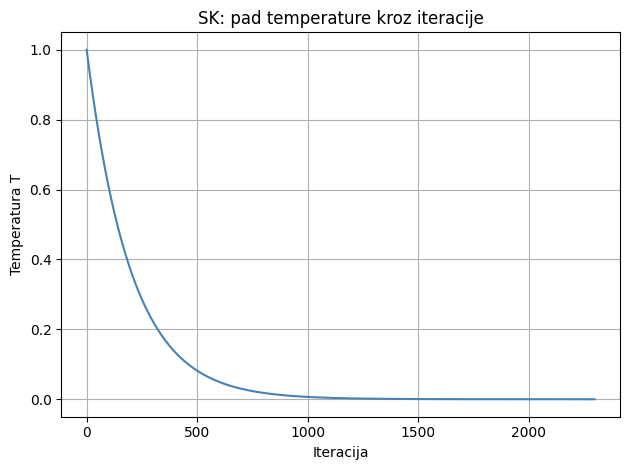

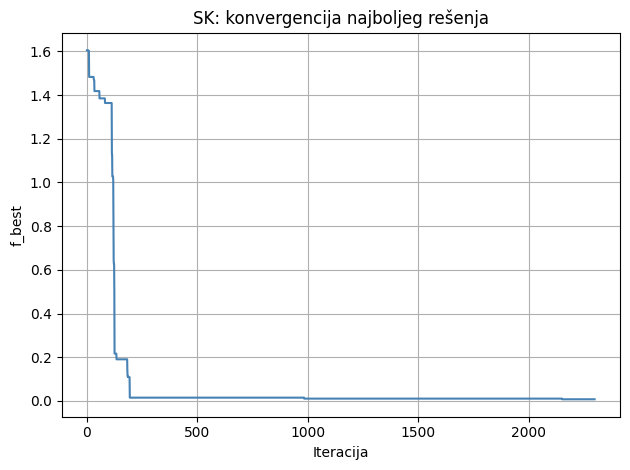

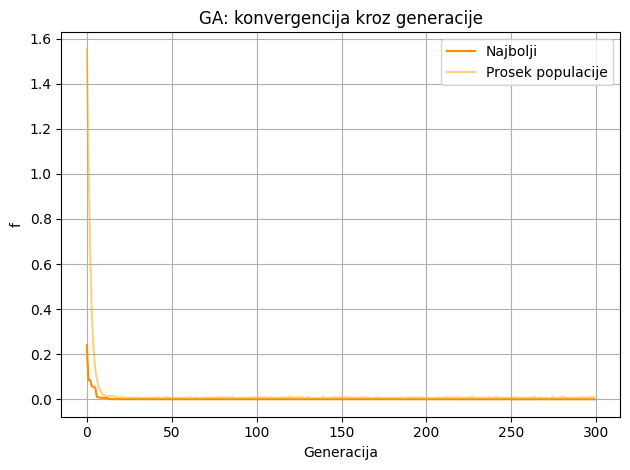

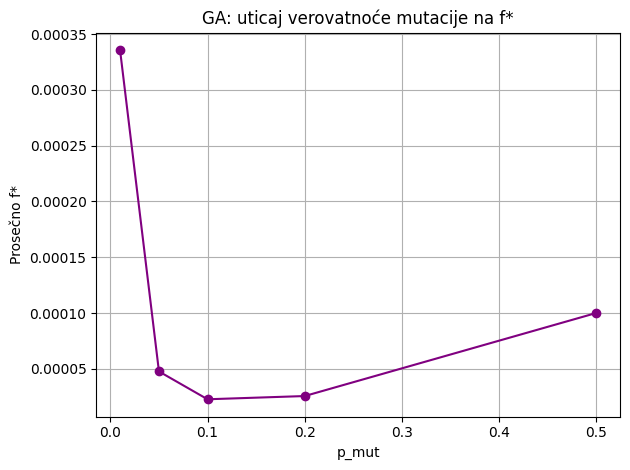

pop=20, gen=100, ops=2000, f*=0.000378
pop=50, gen=100, ops=5000, f*=0.000117
pop=50, gen=300, ops=15000, f*=0.000040
pop=100, gen=300, ops=30000, f*=0.000023
pop=200, gen=300, ops=60000, f*=0.000007
pop=200, gen=500, ops=100000, f*=0.000005


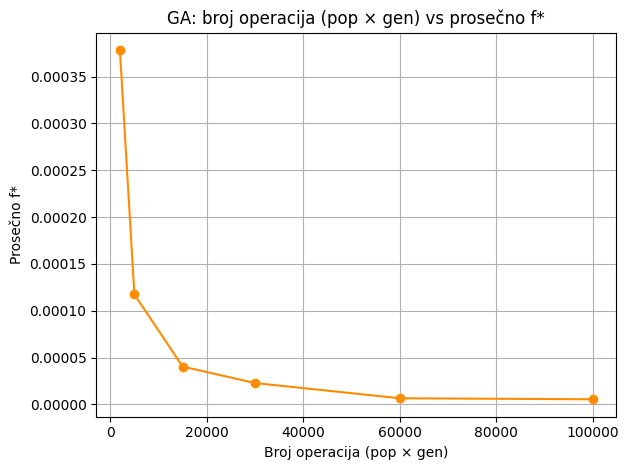

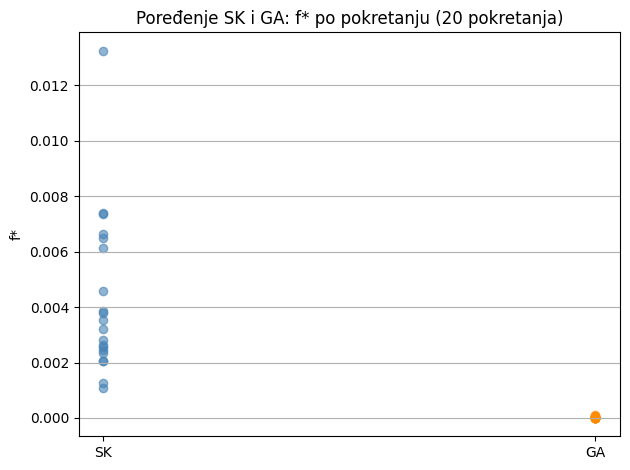

In [22]:
_, _, ist_f_sk, ist_temp = simulirano_kaljenje(seed=0)
_, _, ist_best_ga, ist_avg_ga = genetski_algoritam(seed=0)


plt.figure()
plt.plot(ist_temp, color='steelblue')
plt.title('SK: pad temperature kroz iteracije')
plt.xlabel('Iteracija')
plt.ylabel('Temperatura T')
plt.grid(True)
plt.tight_layout()
plt.show()

plt.figure()
plt.plot(ist_f_sk, color='steelblue')
plt.title('SK: konvergencija najboljeg rešenja')
plt.xlabel('Iteracija')
plt.ylabel('f_best')
plt.grid(True)
plt.tight_layout()
plt.show()


plt.figure()
plt.plot(ist_best_ga, color='darkorange', label='Najbolji')
plt.plot(ist_avg_ga,  color='orange', alpha=0.5, label='Prosek populacije')
plt.title('GA: konvergencija kroz generacije')
plt.xlabel('Generacija')
plt.ylabel('f')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


p_mut_vrednosti = [0.01, 0.05, 0.1, 0.2, 0.5]
proseci = []
for pm in p_mut_vrednosti:
    res = [genetski_algoritam(p_mut=pm, seed=s)[1] for s in range(15)]
    proseci.append(np.mean(res))

plt.figure()
plt.plot(p_mut_vrednosti, proseci, 'o-', color='purple')
plt.title('GA: uticaj verovatnoće mutacije na f*')
plt.xlabel('p_mut')
plt.ylabel('Prosečno f*')
plt.grid(True)
plt.tight_layout()
plt.show()

# Grafik — adekvatnost populacije i broja iteracija
kombinacije = [
    (20,  100),
    (50,  100),
    (50,  300),
    (100, 300),
    (200, 300),
    (200, 500),
]

ops_lista  = []
f_lista    = []

for pop_size, n_gen in kombinacije:
    rezultati = []
    for s in range(15):
        _, fv, _, _ = genetski_algoritam(pop_size=pop_size, 
                                          n_gen=n_gen, 
                                          seed=s)
        rezultati.append(fv)
    ops_lista.append(pop_size * n_gen)
    f_lista.append(np.mean(rezultati))
    print(f"pop={pop_size}, gen={n_gen}, ops={pop_size*n_gen}, f*={np.mean(rezultati):.6f}")

plt.figure()
plt.plot(ops_lista, f_lista, 'o-', color='darkorange')
plt.title('GA: broj operacija (pop × gen) vs prosečno f*')
plt.xlabel('Broj operacija (pop × gen)')
plt.ylabel('Prosečno f*')
plt.grid(True)
plt.tight_layout()
plt.show()

proseci = [sk_rezultati.mean(), ga_rezultati.mean()]
stdovi  = [sk_rezultati.std(),  ga_rezultati.std()]

plt.figure()
plt.scatter(['SK'] * 20, sk_rezultati, color='steelblue', alpha=0.6, label='SK')
plt.scatter(['GA'] * 20, ga_rezultati, color='darkorange', alpha=0.6, label='GA')
plt.title('Poređenje SK i GA: f* po pokretanju (20 pokretanja)')
plt.ylabel('f*')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

Optimizacija rojem čestica

In [31]:
def optimizacija_rojem_cestica(n_cestica=30, n_iter=200, 
                                w=0.7, c1=1.5, c2=1.5, 
                                seed=None):
    
    rng = np.random.default_rng(seed)
    
    pozicije = rng.uniform(-1, 1, size=(n_cestica, 3))
    brzine   = rng.uniform(-0.1, 0.1, size=(n_cestica, 3))
    
    pbest        = pozicije.copy()
    pbest_f      = np.array([f(p) for p in pbest])
    
    gbest_idx    = np.argmin(pbest_f)
    gbest        = pbest[gbest_idx].copy()
    gbest_f      = pbest_f[gbest_idx]
    
    istorija_best = [gbest_f]
    istorija_avg  = [pbest_f.mean()]
    
    for _ in range(n_iter):
        r1 = rng.random(size=(n_cestica, 3))
        r2 = rng.random(size=(n_cestica, 3))
        
        brzine = (w * brzine 
                  + c1 * r1 * (pbest   - pozicije)
                  + c2 * r2 * (gbest   - pozicije))
        
        pozicije = np.clip(pozicije + brzine, -1, 1)
        
        f_vrednosti = np.array([f(p) for p in pozicije])
        
        poboljsano = f_vrednosti < pbest_f
        pbest[poboljsano]   = pozicije[poboljsano].copy()
        pbest_f[poboljsano] = f_vrednosti[poboljsano]
        
        idx = np.argmin(pbest_f)
        if pbest_f[idx] < gbest_f:
            gbest   = pbest[idx].copy()
            gbest_f = pbest_f[idx]
        
        istorija_best.append(gbest_f)
        istorija_avg.append(f_vrednosti.mean())
    
    return gbest, gbest_f, np.array(istorija_best), np.array(istorija_avg)

Prikaz rezultata

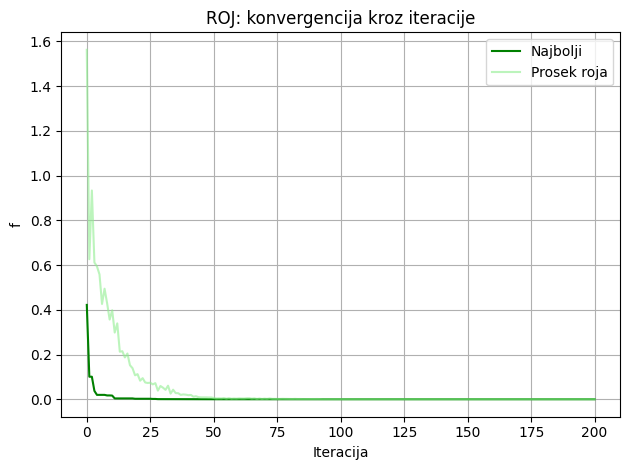

ROJ: prosek = 1.0527380299130553e-13  std = 1.3361238649466936e-13


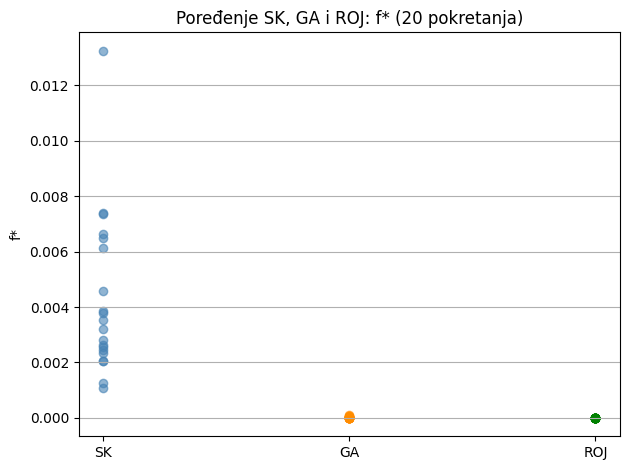

In [32]:
x_roj, f_roj, ist_best_roj, ist_avg_roj = optimizacija_rojem_cestica(seed=0)

plt.figure()
plt.plot(ist_best_roj, color='green', label='Najbolji')
plt.plot(ist_avg_roj,  color='lightgreen', alpha=0.6, label='Prosek roja')
plt.title('ROJ: konvergencija kroz iteracije')
plt.xlabel('Iteracija')
plt.ylabel('f')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

roj_rezultati = []
for i in range(20):
    _, fv, _, _ = optimizacija_rojem_cestica(seed=i)
    roj_rezultati.append(fv)
roj_rezultati = np.array(roj_rezultati)

print("ROJ: prosek =", roj_rezultati.mean(),
      " std =", roj_rezultati.std())

plt.figure()
plt.scatter(['SK'] * 20, sk_rezultati,  color='steelblue',  alpha=0.6)
plt.scatter(['GA'] * 20, ga_rezultati,  color='darkorange', alpha=0.6)
plt.scatter(['ROJ'] * 20, roj_rezultati, color='green',     alpha=0.6)
plt.title('Poređenje SK, GA i ROJ: f* (20 pokretanja)')
plt.ylabel('f*')
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()